In [1]:
# Cell 1: Imports, configuration, helpers, and data validation
%matplotlib inline
import os
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, to_rgba
from IPython.display import Image, display


@dataclass(frozen=True)
class StudentProfile:
    """Student-specific parameters, all derived from the student ID."""
    last_name: str
    student_id: str

    CMAPS = ('viridis', 'plasma', 'magma', 'inferno', 'coolwarm', 'YlOrRd')

    @property
    def id_num(self) -> int:
        return int(self.student_id[-3:])

    @property
    def tag(self) -> str:
        return f"{self.last_name} ({self.student_id})"

    @property
    def color_bar(self) -> str:
        n = self.id_num
        return f"#{(n * 7) % 256:02x}{(n * 3) % 256:02x}{(n * 5) % 256:02x}"

    @property
    def color_line(self) -> str:
        n = self.id_num
        return f"#{(n * 2) % 256:02x}{(n * 9) % 256:02x}{(n * 4) % 256:02x}"

    @property
    def cmap_color(self) -> str:
        return self.CMAPS[self.id_num % len(self.CMAPS)]


profile = StudentProfile(last_name="Gualberto", student_id="TUPM-26-1130")

DATASET_PATH = Path("spotify_dataset") / "spotify_top_1000_tracks.csv"
OUTPUT_DIR = Path("output_appendix_e")
OUTPUT_DIR.mkdir(exist_ok=True)
REQUIRED_COLUMNS = ['track_name', 'artist', 'release_date', 'duration_min', 'popularity']

generated_files = []


def apply_theme() -> None:
    """One consistent, clean visual style for every figure."""
    plt.rcParams.update({
        'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
        'font.family': 'sans-serif', 'axes.titleweight': 'bold', 'axes.titlesize': 13,
        'axes.labelsize': 11, 'axes.spines.top': False, 'axes.spines.right': False,
        'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': '--', 'axes.axisbelow': True,
    })


def fmt_duration(minutes: float) -> str:
    """Convert decimal minutes to m:ss (e.g. 6.77 -> '6:46')."""
    seconds = int(round(minutes * 60))
    return f"{seconds // 60}:{seconds % 60:02d}"


def save_figure(fig, filename: str) -> Path:
    """Save a figure into the output folder and register it."""
    path = OUTPUT_DIR / f"{profile.last_name}_{profile.student_id}_{filename}"
    fig.savefig(path)
    generated_files.append(path)
    return path


def load_dataset(path: Path) -> pd.DataFrame:
    """Load, validate, and clean the Spotify dataset, reporting what was changed."""
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found: {path.resolve()}")

    raw = pd.read_csv(path, encoding="utf-8")
    missing = [c for c in REQUIRED_COLUMNS if c not in raw.columns]
    if missing:
        raise KeyError(f"Missing required column(s): {missing}. Found: {list(raw.columns)}")

    data = raw.copy()
    for col in ('track_name', 'artist'):
        data[col] = data[col].astype(str).str.strip()
    for col in ('duration_min', 'popularity'):
        data[col] = pd.to_numeric(data[col], errors='coerce')
    data['release_date'] = pd.to_datetime(data['release_date'], errors='coerce')
    data['year'] = data['release_date'].dt.year

    before = len(data)
    data = data.drop_duplicates(subset=['track_name', 'artist'], keep='first')

    print("DATA QUALITY REPORT")
    print(f"  Rows read                 : {before}")
    print(f"  Duplicates removed        : {before - len(data)}")
    print(f"  Missing/invalid durations : {int(data['duration_min'].isna().sum())}")
    print(f"  Missing/invalid popularity: {int(data['popularity'].isna().sum())}")
    print(f"  Missing/invalid dates     : {int(data['year'].isna().sum())}")
    print(f"  Rows available            : {len(data)}")
    return data


apply_theme()
df = load_dataset(DATASET_PATH)

print()
print("Student    :", profile.tag)
print("color_bar  :", profile.color_bar)
print("color_line :", profile.color_line)
print("cmap_color :", profile.cmap_color)

DATA QUALITY REPORT
  Rows read                 : 1000
  Duplicates removed        : 29
  Missing/invalid durations : 0
  Missing/invalid popularity: 0
  Missing/invalid dates     : 21
  Rows available            : 971

Student    : Gualberto (TUPM-26-1130)
color_bar  : #8e868a
color_line : #049208
cmap_color : coolwarm


,track_name,artist,duration_min,duration_mm:ss
Rank,,,,
1,Lost Boy,Jaden,9.50,9:30
2,I'm Getting Ready,Tasha Cobbs Leonard,8.44,8:26
3,Mirrors,Justin Timberlake,8.07,8:04
4,What Goes Around.../...Comes Around (Interlude),Justin Timberlake,7.48,7:29
5,Achilles Come Down,Gang of Youths,7.04,7:02
6,Never Let Go (Of Me),Baltra,6.91,6:55
7,House Of Balloons / Glass Table Girls,The Weeknd,6.75,6:45
8,Stan,Eminem,6.74,6:44
9,Galvanize,The Chemical Brothers,6.56,6:34


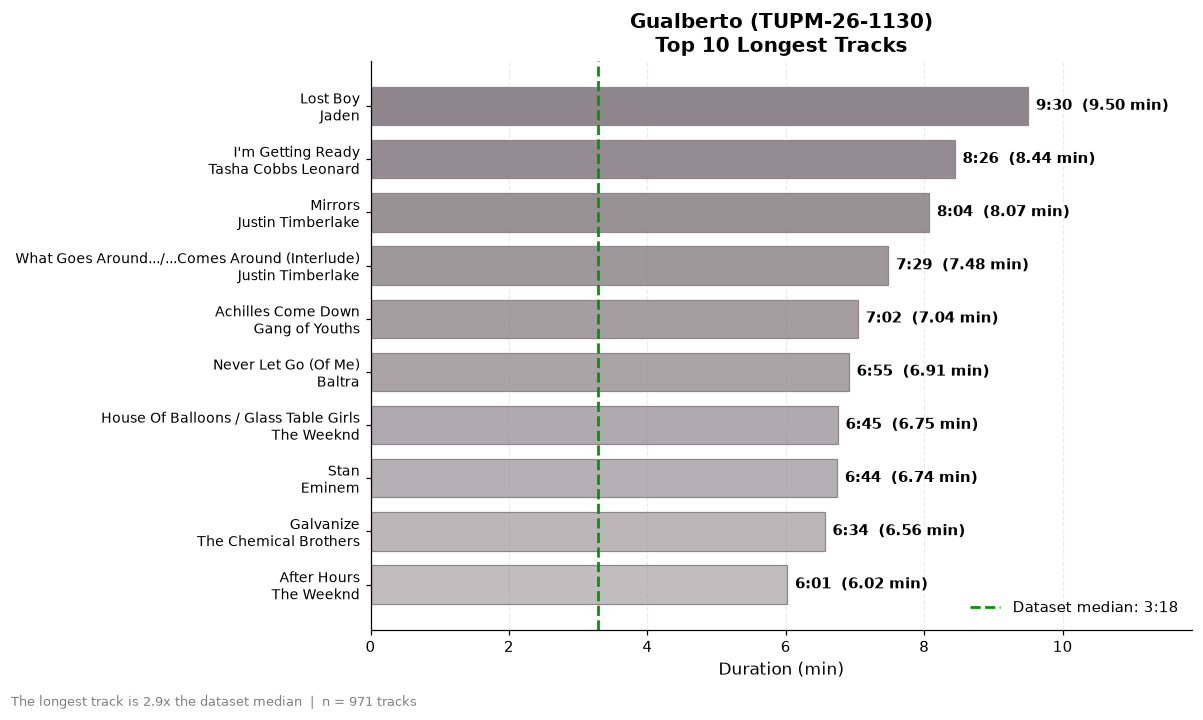

In [2]:
# Cell 2: Exercise 1 - Identify Longest Tracks
TOP_N = 10

valid = df.dropna(subset=['duration_min'])
top10 = (valid.nlargest(TOP_N, 'duration_min')[['track_name', 'artist', 'duration_min']]
              .reset_index(drop=True))
top10.index = top10.index + 1
top10.index.name = 'Rank'
top10['duration_mm:ss'] = top10['duration_min'].map(fmt_duration)
top10['duration_min'] = top10['duration_min'].round(2)

median_duration = valid['duration_min'].median()
longest_ratio = top10['duration_min'].iloc[0] / median_duration

display(top10)

fig, ax = plt.subplots(figsize=(11, 6.5))
y = np.arange(TOP_N)
shades = [to_rgba(profile.color_bar, a) for a in np.linspace(1.0, 0.55, TOP_N)]

ax.barh(y, top10['duration_min'], color=shades, edgecolor=profile.color_bar,
        linewidth=0.8, height=0.72)
ax.set_yticks(y)
ax.set_yticklabels([f"{t}\n{a}" for t, a in zip(top10['track_name'], top10['artist'])], fontsize=9)
ax.invert_yaxis()

x_max = top10['duration_min'].max()
for yi, minutes, label in zip(y, top10['duration_min'], top10['duration_mm:ss']):
    ax.text(minutes + x_max * 0.012, yi, f"{label}  ({minutes:.2f} min)",
            va='center', fontsize=9.5, fontweight='bold')

ax.axvline(median_duration, color=profile.color_line, linestyle='--', linewidth=1.8,
           label=f"Dataset median: {fmt_duration(median_duration)}")
ax.set_xlim(0, x_max * 1.25)
ax.set_xlabel('Duration (min)')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right', frameon=False)
ax.set_title(f"{profile.tag}\nTop {TOP_N} Longest Tracks")
fig.text(0.01, 0.005,
         f"The longest track is {longest_ratio:.1f}x the dataset median  |  n = {len(valid)} tracks",
         fontsize=8.5, color='gray')

fig.tight_layout(rect=(0, 0.02, 1, 1))
save_figure(fig, 'ex1_top10_longest.png')
top10.to_csv(OUTPUT_DIR / f"{profile.last_name}_{profile.student_id}_ex1_top10_longest.csv")
generated_files.append(OUTPUT_DIR / f"{profile.last_name}_{profile.student_id}_ex1_top10_longest.csv")
plt.show()

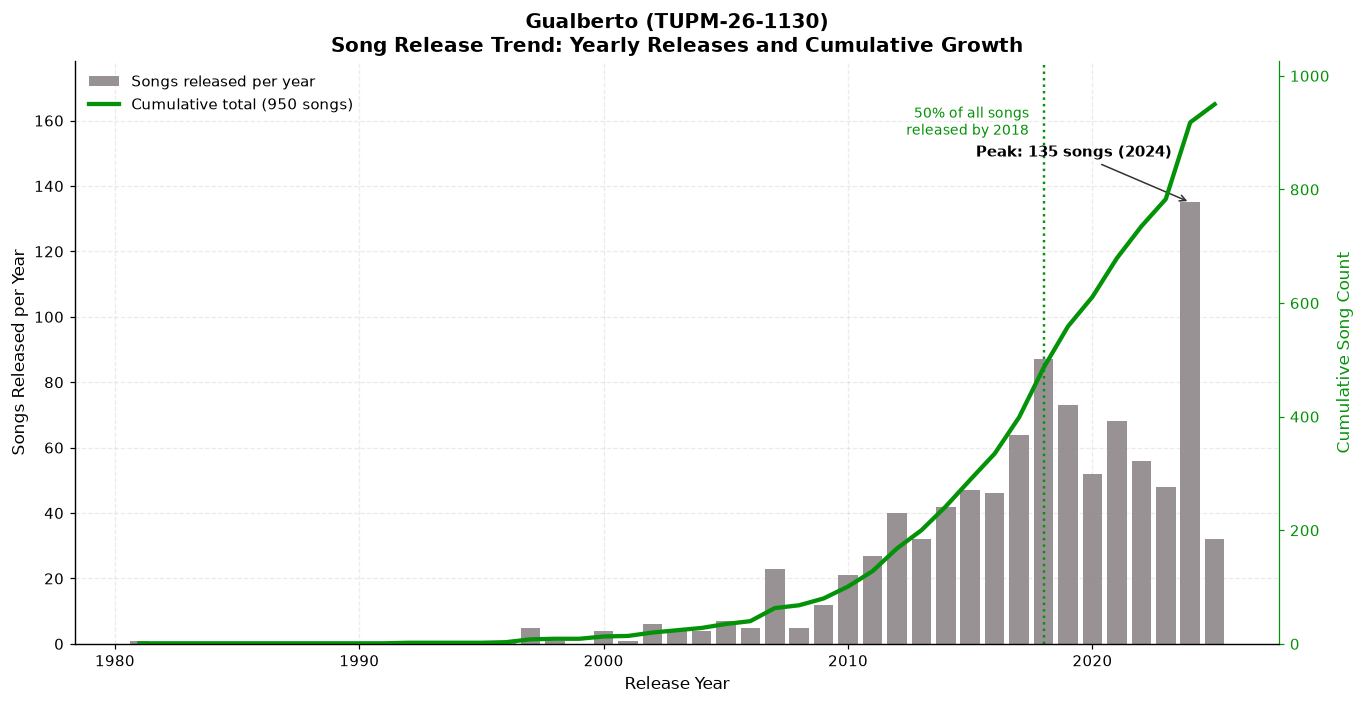

In [3]:
# Cell 3: Exercise 2 - Song Release Trend (yearly bars + cumulative line)
dated = df.dropna(subset=['year']).copy()
dated['year'] = dated['year'].astype(int)

# Reindex over the full year range so years with zero releases are not skipped
full_range = range(dated['year'].min(), dated['year'].max() + 1)
yearly_counts = dated.groupby('year').size().reindex(full_range, fill_value=0)
cumulative = yearly_counts.cumsum()

peak_year = int(yearly_counts.idxmax())
peak_count = int(yearly_counts.max())
half_year = int(cumulative[cumulative >= cumulative.iloc[-1] / 2].index[0])
total_songs = int(cumulative.iloc[-1])

trend = pd.DataFrame({'songs_released': yearly_counts, 'cumulative_songs': cumulative})
trend.index.name = 'year'

fig, ax1 = plt.subplots(figsize=(12.5, 6.5))

bars = ax1.bar(yearly_counts.index, yearly_counts.values, color=profile.color_bar,
               width=0.8, alpha=0.9)
ax1.set_xlabel('Release Year')
ax1.set_ylabel('Songs Released per Year')
ax1.set_ylim(0, peak_count * 1.32)

ax2 = ax1.twinx()
ax2.spines['right'].set_visible(True)
ax2.spines['right'].set_color(profile.color_line)
(line,) = ax2.plot(cumulative.index, cumulative.values, color=profile.color_line, linewidth=2.8)
ax2.set_ylabel('Cumulative Song Count', color=profile.color_line)
ax2.tick_params(axis='y', colors=profile.color_line)
ax2.set_ylim(0, total_songs * 1.08)
ax2.grid(False)

# Keep the label inside the plot when the peak sits near the right edge
near_right = (peak_year - full_range.start) / max(len(full_range) - 1, 1) > 0.85
ax1.annotate(f"Peak: {peak_count} songs ({peak_year})", xy=(peak_year, peak_count),
             xytext=(-12 if near_right else 0, 30), textcoords='offset points',
             ha='right' if near_right else 'center', fontsize=10, fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='#333333'))

ax1.axvline(half_year, color=profile.color_line, linestyle=':', linewidth=1.6)
ax1.text(half_year - 0.6, peak_count * 1.22, f"50% of all songs\nreleased by {half_year}",
         ha='right', va='top', fontsize=9, color=profile.color_line)

ax1.legend([bars, line], ['Songs released per year', f'Cumulative total ({total_songs:,} songs)'],
           loc='upper left', frameon=False)
ax1.set_title(f"{profile.tag}\nSong Release Trend: Yearly Releases and Cumulative Growth")

fig.tight_layout()
save_figure(fig, 'ex2_release_trend.png')
trend_csv = OUTPUT_DIR / f"{profile.last_name}_{profile.student_id}_ex2_release_trend.csv"
trend.to_csv(trend_csv)
generated_files.append(trend_csv)
plt.show()

GIF saved successfully at: C:\Users\Admin\Lab8_Data_Visualization_Gualberto\output_appendix_e\Gualberto_TUPM-26-1130_ex3_hexbin_density.gif  (31 years, 39 frames)


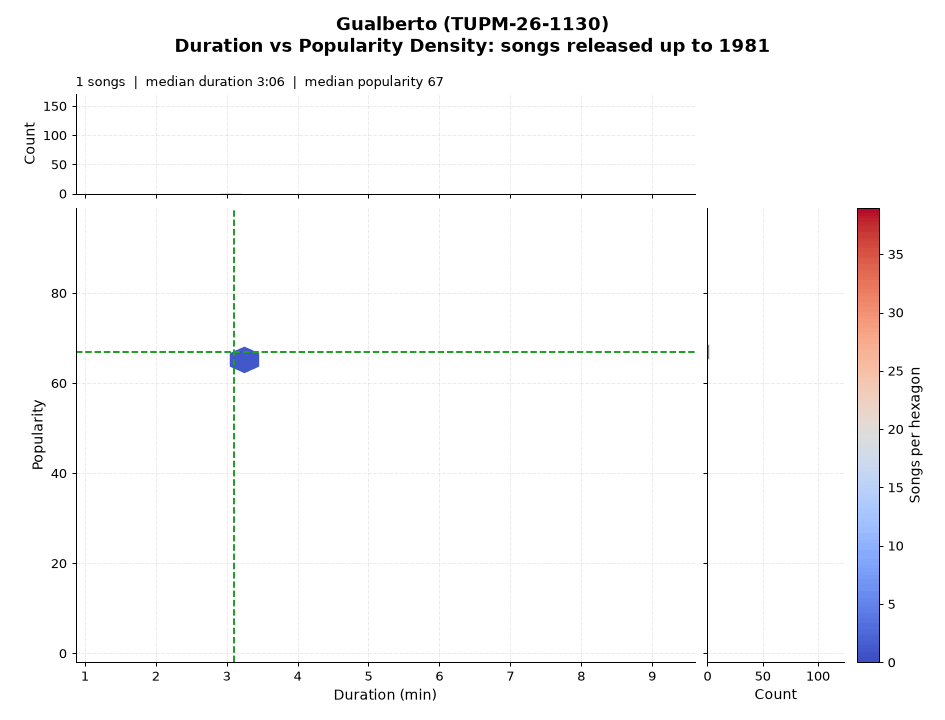

In [4]:
# Cell 4: Exercise 3 - Animated Hexbin Density Map with Marginal Histograms
GRIDSIZE = 22
HIST_BINS = 30
HOLD_FRAMES = 8
FPS = 4

hex_df = df.dropna(subset=['year', 'duration_min', 'popularity']).copy()
hex_df['year'] = hex_df['year'].astype(int)
years = sorted(hex_df['year'].unique())

dur, pop = hex_df['duration_min'], hex_df['popularity']
x0, x1 = dur.min() - 0.1, dur.max() + 0.1
y0, y1 = pop.min() - 2, pop.max() + 2
extent = (x0, x1, y0, y1)

# Fixed scales so every frame is directly comparable
probe_fig, probe_ax = plt.subplots()
vmax = probe_ax.hexbin(dur, pop, gridsize=GRIDSIZE, extent=extent, mincnt=1).get_array().max()
plt.close(probe_fig)

bins_x = np.linspace(x0, x1, HIST_BINS + 1)
bins_y = np.linspace(y0, y1, HIST_BINS + 1)
top_max = np.histogram(dur, bins=bins_x)[0].max() * 1.12
right_max = np.histogram(pop, bins=bins_y)[0].max() * 1.12

fig = plt.figure(figsize=(10.5, 8))
gs = fig.add_gridspec(2, 3, width_ratios=(5, 1.1, 0.18), height_ratios=(1.1, 5),
                      hspace=0.05, wspace=0.05)
ax_top = fig.add_subplot(gs[0, 0])
ax_main = fig.add_subplot(gs[1, 0])
ax_right = fig.add_subplot(gs[1, 1])
cax = fig.add_subplot(gs[1, 2])
fig.subplots_adjust(top=0.87, left=0.08, right=0.93, bottom=0.08)
suptitle = fig.suptitle("", fontsize=14, fontweight='bold', y=0.98)
fig.colorbar(ScalarMappable(norm=Normalize(0, vmax), cmap=profile.cmap_color),
             cax=cax, label='Songs per hexagon')


def update(frame: int) -> None:
    """Draw one frame: all songs released up to the current year."""
    year = years[min(frame, len(years) - 1)]
    subset = hex_df[hex_df['year'] <= year]
    med_dur, med_pop = subset['duration_min'].median(), subset['popularity'].median()

    for axis in (ax_top, ax_main, ax_right):
        axis.clear()

    ax_main.hexbin(subset['duration_min'], subset['popularity'], gridsize=GRIDSIZE,
                   cmap=profile.cmap_color, extent=extent, mincnt=1, vmin=0, vmax=vmax)
    ax_main.axvline(med_dur, color=profile.color_line, linestyle='--', linewidth=1.4)
    ax_main.axhline(med_pop, color=profile.color_line, linestyle='--', linewidth=1.4)
    ax_main.set_xlim(x0, x1)
    ax_main.set_ylim(y0, y1)
    ax_main.set_xlabel('Duration (min)')
    ax_main.set_ylabel('Popularity')

    ax_top.hist(subset['duration_min'], bins=bins_x, color=profile.color_bar,
                edgecolor='white', linewidth=0.4)
    ax_top.set_xlim(x0, x1)
    ax_top.set_ylim(0, top_max)
    ax_top.tick_params(labelbottom=False)
    ax_top.set_ylabel('Count')

    ax_right.hist(subset['popularity'], bins=bins_y, orientation='horizontal',
                  color=profile.color_bar, edgecolor='white', linewidth=0.4)
    ax_right.set_ylim(y0, y1)
    ax_right.set_xlim(0, right_max)
    ax_right.tick_params(labelleft=False)
    ax_right.set_xlabel('Count')

    suptitle.set_text(f"{profile.tag}\nDuration vs Popularity Density: songs released up to {year}")
    ax_top.set_title(f"{len(subset):,} songs  |  median duration {fmt_duration(med_dur)}"
                     f"  |  median popularity {med_pop:.0f}", loc='left', fontsize=10,
                     fontweight='normal')


frame_sequence = list(range(len(years))) + [len(years) - 1] * HOLD_FRAMES
ani = FuncAnimation(fig, update, frames=frame_sequence, interval=1000 // FPS, repeat=False)

gif_path = OUTPUT_DIR / f"{profile.last_name}_{profile.student_id}_ex3_hexbin_density.gif"
ani.save(gif_path, writer=PillowWriter(fps=FPS), dpi=90)
generated_files.append(gif_path)
print(f"GIF saved successfully at: {gif_path.resolve()}  ({len(years)} years, {len(frame_sequence)} frames)")

update(len(years) - 1)
save_figure(fig, 'ex3_final_frame.png')
plt.close(fig)
display(Image(filename=str(gif_path)))